# 第 12 堂：過度擬合與欠擬合
LESSON 12 · OVERFITTING & UNDERFITTING

### 本堂學習目標
學完後，你應該能夠：
1. 說出**欠擬合**、**過度擬合**、**剛剛好**三種狀況的差別。
2. 只看「訓練分數」和「測試分數」，就判斷模型是哪一種狀況。
3. 知道什麼叫**模型複雜度**，以及 K、樹的深度、多項式次方怎麼影響它。
4. 畫出「複雜度 vs 分數」的曲線，找出最好的設定。
5. 知道遇到過度擬合或欠擬合時，該怎麼改善。

### 本堂上課順序
| 順序 | 內容 |
| :--- | :--- |
| 0. 錯題複習 | 加強練習第 2、14、15 題：Recall 的分母 |
| 1. 生活例子 | 三種準備考試的學生 |
| 2. 概念解說 | 欠擬合、過度擬合、泛化能力、模型複雜度 |
| 3. 程式教學 | 彎曲的資料 → 三條線比一比 → 複雜度曲線 → 決策樹與 KNN |
| 4. 逐行解析 | 每段程式後面都有解析表 |
| 5. 實際練習 | 4 個練習，附參考解答 |
| 6. 小考驗收 | 自我檢查，再回對話做小考 |

---
## 零、錯題複習：Recall 的分母，永遠是「真的是」的人數

加強練習錯的三題（第 2、14、15 題）都錯在同一個地方：**把「模型判定是」的人數，當成 Recall 的分母。**

| 指標 | 分母 | 會不會隨門檻改變？ |
| :--- | :--- | :--- |
| **Recall** | **真的**流失的人數（四格表「上面那列」加起來） | **不會**，事實就是事實 |
| **Precision** | 模型**判定**流失的人數（四格表「左邊那欄」加起來） | **會**，門檻越低判越多人 |

檢查方法：算 Recall 前先問自己：「**這份資料裡，真的流失的總共幾個人？**」這個數字不管門檻怎麼調，都不會變。

這一堂會一直看到「訓練分數」和「測試分數」，用的是**正確率**和 **R²**，暫時不會用到 Recall。但第 18～20 堂的專案會再用到，到時候記得這張表。

---
## 一、生活例子：三種準備考試的學生

期末考前，老師發了 100 題練習題。三位同學的準備方式不一樣：

| 學生 | 準備方式 | 練習題考幾分 | 期末考（新題目）考幾分 | 狀況 |
| :--- | :--- | :--- | :--- | :--- |
| 小懶 | 只翻了一下課本，什麼都沒弄懂 | 50 | 45 | **欠擬合**：學太少 |
| 小背 | 把 100 題的答案**全部背下來** | **100** | 60 | **過度擬合**：背答案 |
| 小懂 | 弄懂每一題的**解題方法** | 90 | **88** | **剛剛好**：真的學會 |

- 小懶：兩次都考很差。問題很明顯，大家都看得出來。
- 小背：練習題滿分，看起來最厲害，但遇到新題目就不行了。**這是最危險的**，因為只看練習題分數會被騙。
- 小懂：練習題沒有滿分，但期末考最好。**這才是我們要的模型。**

模型也會有這三種狀況。第 8 堂說過，我們真正在乎的是模型對**新資料**的表現，這個能力叫做**泛化能力**（Generalization）。小懂的泛化能力最好。

---
## 二、概念解說

### 1. 三種狀況

| 狀況 | 英文 | 白話 | 訓練分數 | 測試分數 |
| :--- | :--- | :--- | :--- | :--- |
| 欠擬合 | Underfitting | 模型太簡單，**學不夠** | 低 | 低 |
| 剛剛好 | Good fit | 學到真正的規律 | 高 | 高（和訓練分數接近） |
| 過度擬合 | Overfitting | 模型太複雜，**背答案**，連資料裡的雜訊都背起來了 | **很高**（常常接近滿分） | **明顯比訓練分數低** |

「擬合」（fit）就是 `fit()` 的那個 fit，意思是「讓模型貼合資料」。
- 欠擬合 = 貼得不夠
- 過度擬合 = 貼得太過頭

### 2. 只看兩個分數就能診斷

| 訓練分數 | 測試分數 | 診斷 |
| :--- | :--- | :--- |
| 低 | 低 | **欠擬合** |
| 高 | 高，而且兩個很接近 | **剛剛好** |
| 很高 | 低很多（差距大） | **過度擬合** |

> **記憶方式：先看訓練分數高不高（有沒有學到），再看兩個分數差多少（是不是背答案）。**

### 3. 什麼是「雜訊」？
真實資料一定有一些**隨機的誤差**。例如第 9 堂的計程車收據，同樣 10 公里，有時候塞車多 10 元、有時候少 5 元。
這些誤差**沒有規律、下一次也不會一樣**，叫做**雜訊**（Noise）。

- 好的模型：學**規律**，忽略雜訊。
- 過度擬合的模型：連雜訊都背起來，以為「10 公里就是要多 10 元」，下一次就猜錯了。

### 4. 模型複雜度：控制「學多少」的旋鈕
每個模型都有參數可以控制它有多「複雜」（能記住多少細節）：

| 模型 | 旋鈕 | 往哪邊轉會變複雜 | 太複雜 → | 太簡單 → |
| :--- | :--- | :--- | :--- | :--- |
| 決策樹 | `max_depth` | 深度**越大**越複雜 | 背答案 | 學不夠 |
| KNN | `n_neighbors`（K） | K **越小**越複雜 | K=1 背答案 | K 太大，所有人都猜一樣 |
| 多項式迴歸（今天新學） | `degree`（次方） | 次方**越大**越複雜 | 線彎來彎去 | 直線太僵硬 |

注意 KNN 是**反過來**的：K 越小，越容易被單一鄰居影響，越複雜。

### 5. 怎麼改善？

| 狀況 | 改善方法 |
| :--- | :--- |
| **欠擬合** | 換更複雜的模型（樹加深、K 變小、次方加大）／加入更多有用的特徵 |
| **過度擬合** | 換更簡單的模型（樹變淺、K 變大、次方降低）／收集更多資料／拿掉沒用的特徵 |

今天的重點，就是學會**找出旋鈕轉到哪裡剛剛好**。

---
## 三、程式教學

### 步驟 0：匯入工具與中文字型設定

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# 中文字型設定（同前幾堂）
import sys, os
import matplotlib.font_manager as fm
if "google.colab" in sys.modules:
    os.system("apt-get -qq install -y fonts-noto-cjk > /dev/null")
noto = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
if os.path.exists(noto):
    fm.fontManager.addfont(noto)
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK JP", "Microsoft JhengHei", "PingFang TC", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

print("準備完成")

準備完成


#### 新的匯入

| 名稱 | 用途 |
| :--- | :--- |
| `PolynomialFeatures` | 多項式特徵：讓直線可以**彎曲**（等一下解釋） |
| `StandardScaler` | 把數字縮放到差不多大小，讓電腦算得準（**第 14 堂**會詳細教，今天只要知道它是幫手） |
| `make_pipeline` | 把好幾個步驟**串成一條生產線**，用起來就像一個模型 |

### 步驟 1：一份「彎曲」的資料

某公司 30 個月的廣告費和銷售額（單位：萬）。
真實世界常常是這樣：**廣告費一開始很有效，但花太多之後，效果就越來越小**（大家都看過廣告了），甚至會下降。

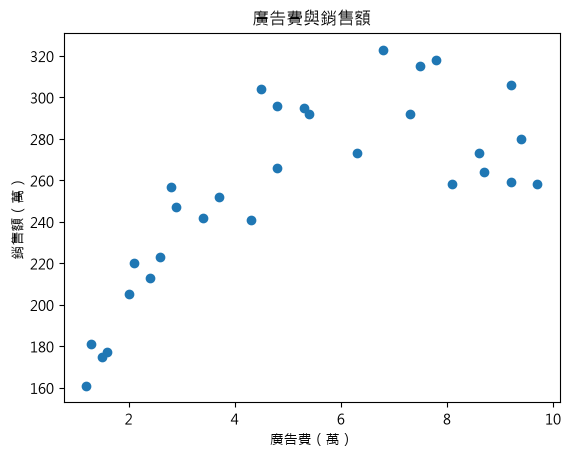

In [2]:
ads = pd.DataFrame({
    "廣告費": [2.0, 2.1, 5.3, 6.8, 7.8, 1.5, 8.1, 9.7, 2.8, 2.4, 3.7, 7.3, 1.3, 4.5, 4.3, 9.4, 3.4, 6.3, 7.5, 1.2, 8.6, 5.4, 8.7, 4.8, 9.2, 9.2, 2.9, 1.6, 2.6, 4.8],
    "銷售額": [205, 220, 295, 323, 318, 175, 258, 258, 257, 213, 252, 292, 181, 304, 241, 280, 242, 273, 315, 161, 273, 292, 264, 296, 259, 306, 247, 177, 223, 266]
})

plt.scatter(ads["廣告費"], ads["銷售額"])
plt.title("廣告費與銷售額")
plt.xlabel("廣告費（萬）")
plt.ylabel("銷售額（萬）")
plt.show()

#### 觀察
點不是排成一條直線，而是像一座**小山丘**：一開始往上升，到 6～7 萬左右就差不多到頂，之後持平甚至往下。
**第 9 堂的線性迴歸只能畫直線**，碰到這種彎曲的資料會怎麼樣？我們來比較三種模型。

### 步驟 2：切分資料

In [3]:
X = ads[["廣告費"]]
y = ads["銷售額"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("訓練集：", X_train.shape, "測試集：", X_test.shape)

訓練集： (21, 1) 測試集： (9, 1)


#### 逐行解析
和第 8 堂一樣：30 筆資料，30% 當測試集（9 筆），剩下 21 筆訓練。這是**迴歸**問題（預測數字），所以不用 `stratify`。

### 步驟 3：讓直線變彎 —— 多項式迴歸

#### 觀念
線性迴歸的公式是：**y = a × x + b**，只能畫直線。

如果把 x 的平方（x²）也加進去，變成：**y = a × x + c × x² + b**，線就可以**彎一次**，畫出山丘的形狀。

再加入 x³、x⁴……，線就可以彎更多次。

| 次方 degree | 公式 | 形狀 |
| :--- | :--- | :--- |
| 1 | a·x + b | 直線 |
| 2 | a·x + c·x² + b | 彎一次（山丘或山谷） |
| 12 | a·x + … + 某數·x¹² + b | 可以彎很多次 |

`PolynomialFeatures(degree=2)` 的工作，就是**自動幫你把 x 變成 x、x²**，再交給 `LinearRegression`。

In [4]:
# 用一個小例子看 PolynomialFeatures 做了什麼
demo = pd.DataFrame({"廣告費": [2, 3]})
poly = PolynomialFeatures(degree=2)
print(poly.fit_transform(demo))

[[1. 2. 4.]
 [1. 3. 9.]]


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `PolynomialFeatures(degree=2)` | 建立「最多到平方」的轉換工具 |
| `poly.fit_transform(demo)` | **新指令**：fit + transform 一次做完，把資料轉換成新的樣子 |

印出來每一列是 `[1, x, x²]`：
- 2 → `[1, 2, 4]`（1、2、2 的平方 4）
- 3 → `[1, 3, 9]`（1、3、3 的平方 9）

最前面的 1 是給截距用的，不用管它。重點是：**一個特徵，變成了好幾個特徵**，線性迴歸就能利用 x² 畫出彎曲的線。

### 步驟 4：三條線比一比（次方 1、2、12）

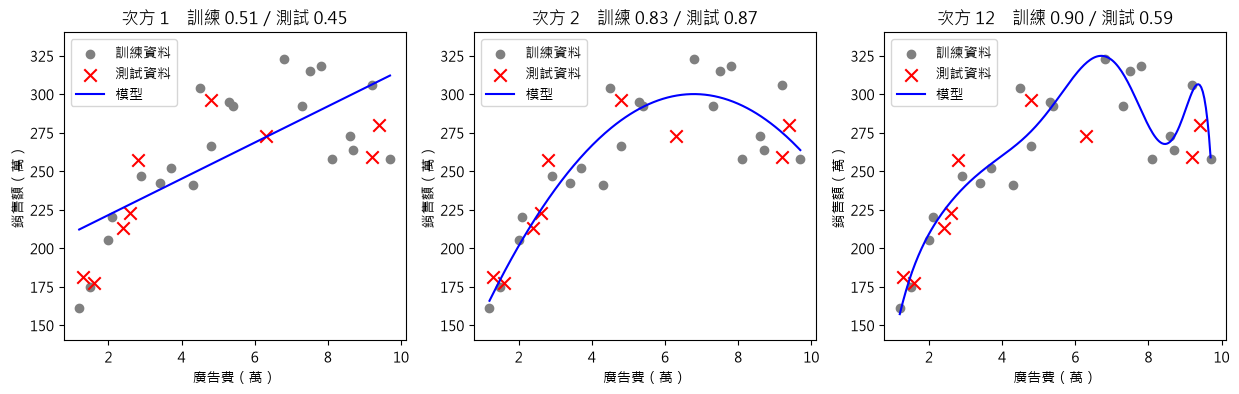

In [5]:
x_line = pd.DataFrame({"廣告費": np.linspace(1.2, 9.7, 200)})

plt.figure(figsize=(15, 4))

for i, deg in enumerate([1, 2, 12]):
    model = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression())
    model.fit(X_train, y_train)

    train_score = model.score(X_train, y_train)
    test_score = model.score(X_test, y_test)

    plt.subplot(1, 3, i + 1)
    plt.scatter(X_train["廣告費"], y_train, color="gray", label="訓練資料")
    plt.scatter(X_test["廣告費"], y_test, color="red", marker="x", s=80, label="測試資料")
    plt.plot(x_line["廣告費"], model.predict(x_line), color="blue", label="模型")
    plt.title(f"次方 {deg}　訓練 {train_score:.2f}／測試 {test_score:.2f}")
    plt.xlabel("廣告費（萬）")
    plt.ylabel("銷售額（萬）")
    plt.ylim(140, 340)
    plt.legend()

plt.show()

#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `np.linspace(1.2, 9.7, 200)` | **新指令**：在 1.2 到 9.7 之間平均取 200 個點。點夠多，畫出來的曲線才會平滑（第 9 堂直線只要 2 個點，曲線需要很多點） |
| `for i, deg in enumerate([1, 2, 12]):` | **新語法**：`enumerate` 讓迴圈同時拿到「第幾個（i = 0、1、2）」和「值（deg = 1、2、12）」。i 用來決定畫在第幾格 |
| `make_pipeline(A, B, C)` | 把三個步驟串起來：先 A 轉成多項式 → 再 B 縮放 → 最後 C 線性迴歸 |
| `model.fit(...)`、`model.score(...)` | 串起來之後，用法和以前的模型**完全一樣** |
| `plt.subplot(1, 3, i + 1)` | 第 8 堂：切成 1 列 3 欄，畫在第 i+1 格 |
| `s=80` | 點的大小，讓測試資料的紅叉比較明顯 |
| `f"次方 {deg}　訓練 {train_score:.2f}"` | **f-string**：字串前面加 f，`{ }` 裡面可以放變數；`:.2f` 代表顯示到小數點後 2 位 |
| `plt.ylim(140, 340)` | 固定 Y 軸範圍，讓三張圖可以公平比較 |

#### 讀三張圖

| 次方 | 圖上看到什麼 | 訓練 | 測試 | 診斷 |
| :--- | :--- | :--- | :--- | :--- |
| **1** | 一條直線，左邊和右邊都離點很遠 | 0.51 | 0.45 | **欠擬合**：太僵硬，抓不到「山丘」的形狀 |
| **2** | 一條平滑的山丘線，穿過點群中間 | 0.83 | **0.87** | **剛剛好** |
| **12** | 線彎來彎去，努力穿過每一個灰點 | **0.90** | 0.59 | **過度擬合**：連雜訊都背了，紅叉（新資料）反而猜不準 |

**次方 12 的訓練分數最高，但它是最差的模型之一。** 這就是為什麼一定要看測試分數。

### 步驟 5：複雜度曲線 —— 把旋鈕從 1 轉到 12

三張圖只看了三個點。接下來用迴圈把次方 1 到 12 全部試一次，把兩個分數畫成曲線。

In [6]:
degrees = []
train_scores = []
test_scores = []

for deg in range(1, 13):
    model = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression())
    model.fit(X_train, y_train)
    degrees.append(deg)
    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

result = pd.DataFrame({"次方": degrees, "訓練分數": train_scores, "測試分數": test_scores})
print(result.round(3))

    次方   訓練分數   測試分數
0    1  0.507  0.446
1    2  0.833  0.865
2    3  0.833  0.862
3    4  0.833  0.862
4    5  0.852  0.815
5    6  0.855  0.798
6    7  0.886  0.644
7    8  0.890  0.627
8    9  0.896  0.606
9   10  0.898  0.601
10  11  0.900  0.597
11  12  0.902  0.592


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `degrees = []` | 建立一個**空清單**，等一下把結果一個一個放進去 |
| `range(1, 13)` | **新指令**：產生 1, 2, 3, …, 12（**不含 13**，結尾的數字不算） |
| `degrees.append(deg)` | **新指令**：`append` = 附加，把一個值加到清單的最後面 |

#### 「第幾輪」的表（照第 11 堂的方法）
| 第幾輪 | deg | 做什麼 | 三個清單變成 |
| :--- | :--- | :--- | :--- |
| 1 | 1 | 訓練次方 1 的模型，算兩個分數 | 各有 1 個值 |
| 2 | 2 | 訓練次方 2 的模型，算兩個分數 | 各有 2 個值 |
| … | … | … | … |
| 12 | 12 | 訓練次方 12 的模型，算兩個分數 | 各有 12 個值 |

迴圈結束後，三個清單各有 12 個值，正好可以組成一張表、畫成一張圖。

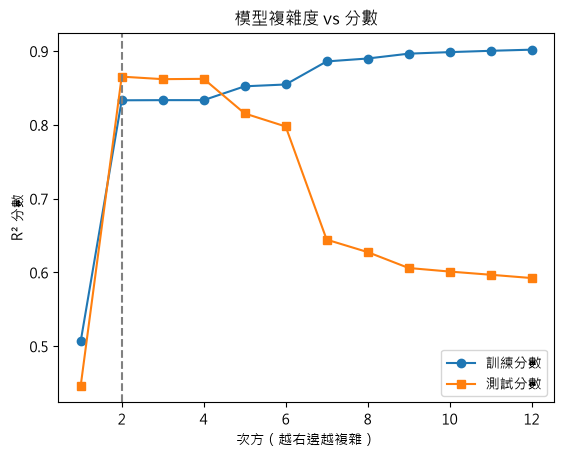

In [7]:
plt.plot(degrees, train_scores, marker="o", label="訓練分數")
plt.plot(degrees, test_scores, marker="s", label="測試分數")
plt.axvline(2, color="gray", linestyle="--")
plt.title("模型複雜度 vs 分數")
plt.xlabel("次方（越右邊越複雜）")
plt.ylabel("R² 分數")
plt.legend()
plt.show()

#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `plt.plot(degrees, train_scores, ...)` | 第 7 堂：折線圖，X 是次方、Y 是分數 |
| `plt.axvline(2, ...)` | **新指令**：在 x = 2 的地方畫一條垂直線（a = axis、v = vertical），標出最佳位置 |

#### 這是今天最重要的一張圖

```
分數
 ↑        訓練分數：一路往上（越複雜，越會背）
 │     ●───●───●───●───●───●───●
 │   ●   ■───■───■
 │  ●              ■───■
 │                        ■───■───■   測試分數：先升後降
 │ ■
 └──────────────────────────────────→ 複雜度
   欠擬合 │ 剛剛好 │      過度擬合
```

| 區域 | 訓練分數 | 測試分數 | 兩條線的距離 |
| :--- | :--- | :--- | :--- |
| 左邊（次方 1） | 低 | 低 | 很近 |
| 中間（次方 2～4） | 高 | **最高** | 很近 |
| 右邊（次方 7 以上） | 越來越高 | 越來越低 | **越拉越開** |

> **兩條線開始分開的地方，就是模型開始背答案的地方。選測試分數最高的那個點。**

這張圖可以用在**任何模型**上，下面換成決策樹和 KNN 試試。

### 步驟 6：決策樹的深度曲線

換成第 11 堂的健身房資料（200 位會員，預測會不會流失）。這格資料很長，**直接執行即可**。

In [8]:
gym = pd.DataFrame({
    "到店次數": [11, 10, 10, 10, 8, 12, 1, 9, 10, 8, 11, 12, 1, 2, 12, 7, 4, 5, 11, 4,
            7, 4, 11, 2, 9, 12, 7, 3, 0, 9, 7, 6, 10, 8, 10, 9, 8, 0, 7, 0,
            8, 12, 11, 3, 12, 5, 6, 3, 8, 3, 12, 4, 0, 1, 6, 4, 9, 7, 5, 12,
            12, 2, 1, 12, 1, 10, 3, 5, 2, 11, 0, 11, 2, 12, 6, 2, 0, 9, 10, 10,
            11, 8, 8, 11, 2, 10, 10, 2, 2, 8, 6, 2, 8, 2, 6, 6, 5, 4, 3, 12,
            4, 0, 5, 2, 11, 10, 2, 11, 1, 0, 7, 9, 6, 9, 9, 8, 6, 7, 3, 11,
            10, 11, 3, 5, 8, 0, 6, 12, 8, 3, 7, 2, 8, 0, 6, 6, 4, 12, 6, 9,
            11, 5, 2, 10, 6, 8, 1, 11, 11, 11, 8, 5, 1, 10, 11, 9, 7, 11, 9, 3,
            10, 3, 9, 6, 10, 2, 6, 1, 12, 6, 4, 4, 11, 5, 4, 4, 12, 3, 12, 11,
            7, 9, 4, 5, 1, 5, 8, 3, 8, 5, 8, 7, 11, 0, 11, 2, 2, 3, 7, 11],
    "會員年資": [3.1, 6.3, 0.5, 4.2, 5.8, 0.1, 4.3, 0.5, 2.6, 3.8, 6.9, 0.6, 0.5, 5.1, 2.2, 5.1, 5.1, 1.6, 0.2, 3.4,
            2.4, 5.4, 6.4, 2.7, 1.7, 6.5, 2.5, 0.3, 4.3, 5.0, 7.5, 3.5, 2.8, 1.7, 4.1, 2.7, 5.4, 4.5, 6.1, 7.2,
            3.8, 0.4, 3.3, 3.6, 2.6, 0.4, 6.1, 7.8, 3.7, 2.6, 3.6, 3.5, 0.0, 7.2, 7.6, 4.5, 1.1, 3.3, 4.1, 3.0,
            1.9, 6.2, 5.0, 3.6, 1.7, 5.1, 7.7, 1.8, 1.3, 0.3, 6.8, 6.1, 5.1, 2.4, 6.2, 0.2, 5.4, 0.8, 3.9, 6.3,
            2.3, 7.8, 6.8, 2.6, 0.4, 2.9, 3.4, 7.6, 7.5, 6.1, 1.9, 7.1, 8.0, 3.7, 5.0, 5.0, 3.6, 3.5, 6.2, 1.6,
            0.3, 2.7, 5.7, 6.8, 0.4, 6.9, 5.3, 6.2, 2.4, 6.0, 0.1, 7.5, 2.7, 6.1, 5.3, 6.5, 7.6, 6.2, 1.9, 2.1,
            1.8, 7.0, 6.4, 7.0, 5.3, 4.4, 0.2, 6.3, 8.0, 3.4, 1.1, 7.0, 1.9, 4.1, 3.0, 5.2, 2.9, 6.5, 3.6, 5.2,
            4.0, 7.1, 2.5, 6.4, 2.5, 6.0, 4.7, 1.6, 5.7, 2.0, 4.6, 0.5, 0.5, 2.4, 4.2, 7.0, 4.8, 5.2, 6.1, 3.3,
            6.9, 0.4, 4.4, 4.7, 7.7, 4.9, 6.9, 7.2, 3.0, 5.5, 3.4, 3.1, 2.6, 4.3, 5.7, 0.6, 2.7, 0.8, 2.4, 7.9,
            3.9, 0.4, 1.7, 3.6, 4.3, 3.8, 3.7, 3.6, 7.2, 1.7, 3.1, 2.0, 1.3, 4.9, 6.3, 4.6, 1.3, 5.3, 7.5, 1.7],
    "客訴次數": [0, 1, 0, 0, 1, 0, 2, 0, 0, 0, 2, 1, 0, 0, 0, 0, 0, 0, 1, 2,
            1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0,
            0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1,
            2, 1, 0, 1, 1, 0, 1, 1, 0, 2, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0,
            1, 0, 0, 1, 0, 1, 0, 3, 1, 1, 0, 1, 2, 0, 1, 1, 1, 0, 0, 1,
            2, 0, 1, 0, 1, 2, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0,
            0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 2, 2, 1, 0, 1, 0, 0, 0, 0,
            0, 0, 0, 0, 2, 0, 2, 0, 1, 0, 1, 2, 1, 1, 3, 0, 1, 0, 0, 0,
            3, 0, 0, 0, 0, 1, 0, 1, 3, 1, 0, 0, 0, 1, 0, 3, 2, 2, 1, 0,
            0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 2, 0],
    "流失標記": [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
            0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
            0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
            0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0,
            0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
            1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
            0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0,
            0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
            0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0,
            0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0]
})
gym["結果"] = np.where(gym["流失標記"] == 1, "流失", "續約")

Xg = gym[["到店次數", "會員年資", "客訴次數"]]
yg = gym["結果"]
Xg_train, Xg_test, yg_train, yg_test = train_test_split(
    Xg, yg, test_size=0.25, random_state=42, stratify=yg
)
print("訓練集：", Xg_train.shape, "測試集：", Xg_test.shape)

訓練集： (150, 3) 測試集： (50, 3)


   深度  訓練正確率  測試正確率
0   1  0.860   0.90
1   2  0.893   0.92
2   3  0.927   0.86
3   4  0.967   0.86
4   5  0.973   0.84
5   6  0.993   0.84
6   7  1.000   0.84
7   8  1.000   0.84
8   9  1.000   0.84
9  10  1.000   0.84


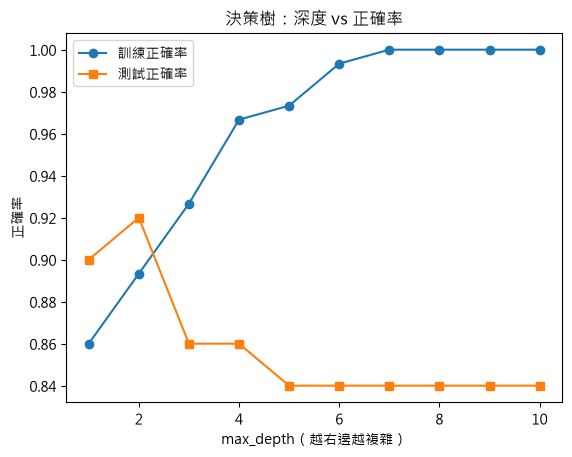

In [9]:
depths = []
tree_train = []
tree_test = []

for depth in range(1, 11):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(Xg_train, yg_train)
    depths.append(depth)
    tree_train.append(tree.score(Xg_train, yg_train))
    tree_test.append(tree.score(Xg_test, yg_test))

print(pd.DataFrame({"深度": depths, "訓練正確率": tree_train, "測試正確率": tree_test}).round(3))

plt.plot(depths, tree_train, marker="o", label="訓練正確率")
plt.plot(depths, tree_test, marker="s", label="測試正確率")
plt.title("決策樹：深度 vs 正確率")
plt.xlabel("max_depth（越右邊越複雜）")
plt.ylabel("正確率")
plt.legend()
plt.show()

#### 逐行解析
和步驟 5 的結構**一模一樣**，只是把模型換成決策樹、旋鈕換成 `max_depth`。這就是 sklearn 的好處：**同一套寫法可以用在任何模型上。**

#### 觀察
| 深度 | 訓練 | 測試 | 診斷 |
| :--- | :--- | :--- | :--- |
| 2 | 0.89 | **0.92** | 最好 |
| 4 | 0.97 | 0.86 | 開始背答案 |
| 7 以上 | **1.00** | 0.84 | 完全背起來了（每位訓練會員都答對） |

深度 7 以上的樹，測試正確率 0.84，剛好等於第 11 堂「一律猜續約」的基準模型。**背了一大堆答案，結果跟什麼都沒學一樣。**

### 步驟 7：KNN 的 K 曲線（旋鈕方向相反！）

    K  訓練正確率  測試正確率
0   1  1.000   0.86
1   3  0.920   0.82
2   5  0.933   0.90
3   7  0.913   0.92
4   9  0.907   0.94
5  15  0.913   0.92
6  25  0.880   0.86
7  41  0.853   0.84
8  61  0.847   0.84


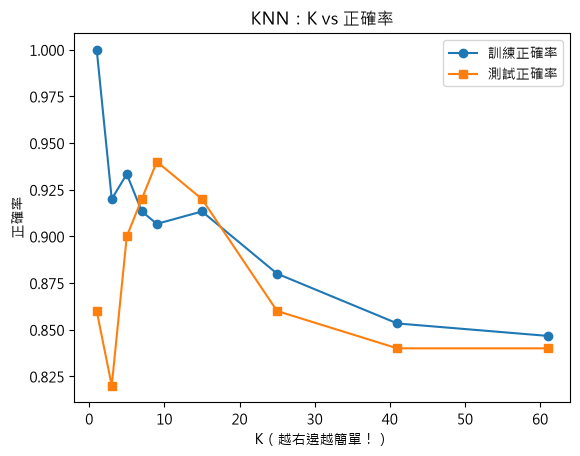

In [10]:
ks = [1, 3, 5, 7, 9, 15, 25, 41, 61]
knn_train = []
knn_test = []

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(Xg_train, yg_train)
    knn_train.append(knn.score(Xg_train, yg_train))
    knn_test.append(knn.score(Xg_test, yg_test))

print(pd.DataFrame({"K": ks, "訓練正確率": knn_train, "測試正確率": knn_test}).round(3))

plt.plot(ks, knn_train, marker="o", label="訓練正確率")
plt.plot(ks, knn_test, marker="s", label="測試正確率")
plt.title("KNN：K vs 正確率")
plt.xlabel("K（越右邊越簡單！）")
plt.ylabel("正確率")
plt.legend()
plt.show()

#### 逐行解析
`ks` 不是用 `range` 產生，而是直接寫一個清單，因為我們只想試幾個特定的 K。其他和步驟 6 一樣。

#### 觀察：方向和決策樹相反

| K | 訓練 | 測試 | 診斷 |
| :--- | :--- | :--- | :--- |
| **1**（最複雜） | **1.00** | 0.86 | **過度擬合**：只聽自己的，等於背答案（第 10 堂） |
| **9** | 0.91 | **0.94** | **剛剛好** |
| **61**（最簡單） | 0.85 | 0.84 | **欠擬合**：問了 61 個鄰居，大部分都是續約，幾乎每個人都猜續約，又變回基準模型 |

| 模型 | 往右轉代表 | 過度擬合在哪一邊 |
| :--- | :--- | :--- |
| 多項式次方、樹的深度 | 越複雜 | **右邊** |
| KNN 的 K | 越簡單 | **左邊** |

**不用死背方向，看兩個分數就能判斷：** 訓練分數很高、測試分數低很多的那一邊，就是過度擬合。

### 步驟 8：重要提醒 —— 這樣選參數其實有一點「作弊」

我們用**測試集分數**來挑最好的次方、深度、K。但測試集應該是「期末考」，是最後才拿出來的。
如果一直看期末考的分數來調整讀書方法，等於**偷看考題**，選出來的模型在真正的新資料上可能沒那麼好。

正確的做法是**再切出一份「模擬考」**，用模擬考來調參數，期末考只在最後用一次。
這個方法叫做**交叉驗證**（Cross-Validation），是**第 15 堂**的主題。今天先用測試集，是為了讓你看懂曲線的意思。

---
## 四、本堂重點整理

### 診斷表（最重要）
| 訓練分數 | 測試分數 | 診斷 | 改善方法 |
| :--- | :--- | :--- | :--- |
| 低 | 低 | **欠擬合** | 模型變複雜、加有用的特徵 |
| 高 | 高且接近 | **剛剛好** | 保持 |
| 很高 | 低很多 | **過度擬合** | 模型變簡單、收集更多資料、拿掉沒用的特徵 |

### 複雜度旋鈕
| 模型 | 參數 | 越複雜 |
| :--- | :--- | :--- |
| 多項式迴歸 | `degree` | 越大 |
| 決策樹 | `max_depth` | 越大 |
| KNN | `n_neighbors` | **越小** |

### 新程式碼
| 程式碼 | 意思 |
| :--- | :--- |
| `PolynomialFeatures(degree)` | 把 x 變成 x、x²、x³…，讓線可以彎 |
| `make_pipeline(A, B, C)` | 把多個步驟串成一個模型 |
| `np.linspace(起, 終, 個數)` | 平均取很多個點，用來畫平滑曲線 |
| `range(1, 13)` | 1 到 12（不含 13） |
| `清單.append(值)` | 把值加到清單最後面 |
| `for i, v in enumerate(清單):` | 同時拿到「第幾個」和「值」 |
| `f"文字 {變數:.2f}"` | 把變數放進文字裡，顯示到小數 2 位 |
| `plt.axvline(x)` | 在 x 的位置畫垂直線 |

### 三句話
1. **訓練分數高不代表模型好**，要看測試分數。
2. **兩條線分開的地方，就是開始背答案的地方。**
3. 最好的模型，是**測試分數最高**的那個複雜度。

---
## 五、實際練習

### 練習一：診斷三個模型
用 `print` 寫下每個模型是欠擬合、剛剛好，還是過度擬合，以及你會怎麼改善。

| 模型 | 訓練分數 | 測試分數 |
| :--- | :--- | :--- |
| A | 0.99 | 0.62 |
| B | 0.55 | 0.52 |
| C | 0.88 | 0.86 |

In [ ]:
# 練習一：在這裡寫你的答案
print("A:過度擬合(訓練幾乎滿分，測試分數低)。改善:把模型變簡單。例如降低樹的深度或加大K，或收集更多資料")
print("B:欠擬合(訓練、測試都低分)。改善:調高模型複雜度。例如加深樹、縮小K、提高次方，或加入更有用的特徵")
print("C:剛剛好(兩個分數都高，且分數接近)")

In [ ]:
# 練習一 參考解答
print("A：過度擬合（訓練幾乎滿分、測試低很多）。改善：把模型變簡單，例如降低樹的深度或加大 K，或收集更多資料。")
print("B：欠擬合（兩個分數都低）。改善：把模型變複雜，例如加深樹、縮小 K、提高次方，或加入更多有用的特徵。")
print("C：剛剛好（兩個都高，而且很接近）。")

### 練習二：次方 3 的模型
仿照步驟 4，只訓練 `degree=3` 的模型，印出訓練分數和測試分數，並畫出它的曲線。它和次方 2 比起來怎麼樣？

訓練: 0.833
測試: 0.862


<function matplotlib.pyplot.show(close=None, block=None)>

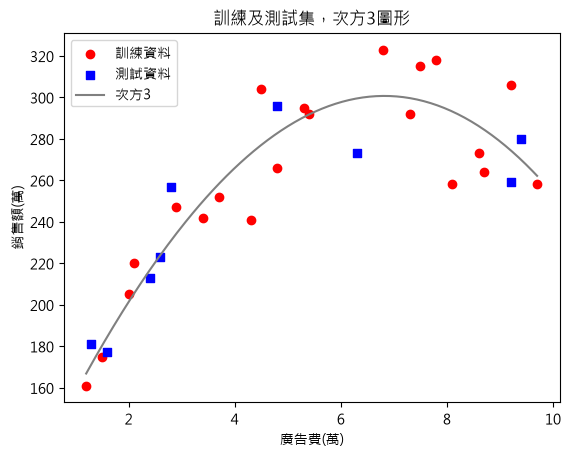

In [12]:
# 練習二：在這裡寫你的程式
model3 = make_pipeline(PolynomialFeatures(3), StandardScaler(), LinearRegression())
model3.fit(X_train, y_train)
print("訓練:", round(model3.score(X_train, y_train), 3))
print("測試:", round(model3.score(X_test, y_test), 3))

plt.scatter(X_train["廣告費"], y_train, color="red", label="訓練資料")
plt.scatter(X_test["廣告費"], y_test, color="blue", label="測試資料", marker="s")
plt.plot(x_line["廣告費"], model3.predict(x_line), color="gray", label="次方3")
plt.title("訓練及測試集，次方3圖形")
plt.legend()
plt.xlabel("廣告費(萬)")
plt.ylabel("銷售額(萬)")
plt.show

訓練： 0.833
測試： 0.862


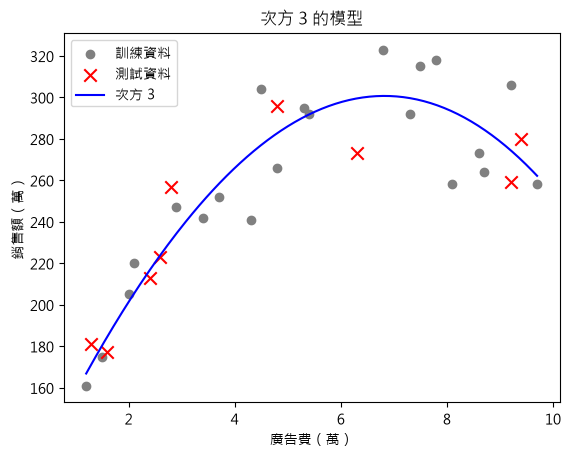

In [13]:
# 練習二 參考解答
model3 = make_pipeline(PolynomialFeatures(3), StandardScaler(), LinearRegression())
model3.fit(X_train, y_train)
print("訓練：", round(model3.score(X_train, y_train), 3))
print("測試：", round(model3.score(X_test, y_test), 3))

plt.scatter(X_train["廣告費"], y_train, color="gray", label="訓練資料")
plt.scatter(X_test["廣告費"], y_test, color="red", marker="x", s=80, label="測試資料")
plt.plot(x_line["廣告費"], model3.predict(x_line), color="blue", label="次方 3")
plt.title("次方 3 的模型")
plt.xlabel("廣告費（萬）")
plt.ylabel("銷售額（萬）")
plt.legend()
plt.show()
# 次方 3 和次方 2 的分數幾乎一樣，曲線也很像。兩個都可以，通常選比較簡單的次方 2。

### 練習三：用 range 和 append 畫 KNN 曲線
用 `range(1, 31, 2)`（1、3、5、…、29，每次跳 2）當 K，畫出 KNN 在健身房資料的「訓練 vs 測試正確率」曲線，並印出測試正確率最高的 K。
提示：`range(起, 終, 間隔)` 的第三個數字是每次跳幾格。找最大值的位置可以用 `np.argmax(清單)`。

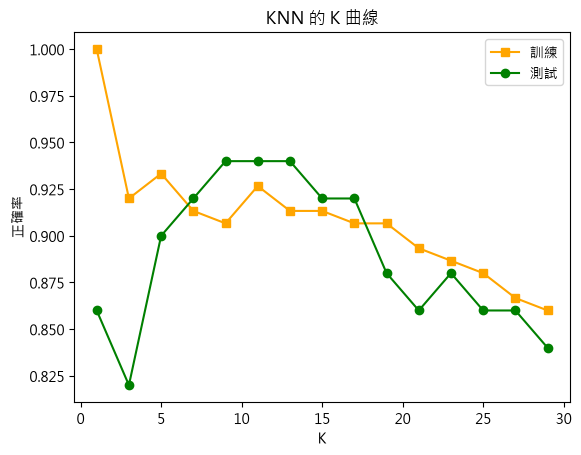

最好的K: 9 測試正確率: 0.907


In [17]:
# 練習三：在這裡寫你的程式
k_list = []
tr = []
te = []
for k in range(1, 31, 2):
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(Xg_train, yg_train)
    k_list.append(k)
    tr.append(m.score(Xg_train, yg_train))
    te.append(m.score(Xg_test, yg_test))

plt.plot(k_list, tr, color="orange", label="訓練", marker="s")
plt.plot(k_list, te, color="green", label="測試", marker="o")
plt.xlabel("K")
plt.ylabel("正確率")
plt.title("KNN 的 K 曲線")
plt.legend()
plt.show()

best = np.argmax(te)
print("最好的K:", k_list[best], "測試正確率:", round(tr[best],3 ))

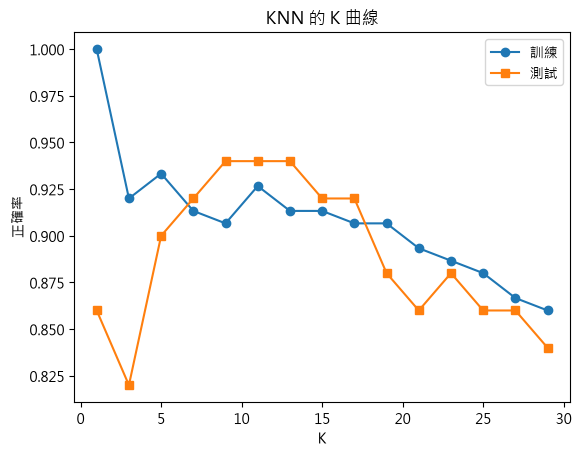

最好的 K： 9  測試正確率： 0.94


In [15]:
# 練習三 參考解答
k_list = []
tr = []
te = []
for k in range(1, 31, 2):
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(Xg_train, yg_train)
    k_list.append(k)
    tr.append(m.score(Xg_train, yg_train))
    te.append(m.score(Xg_test, yg_test))

plt.plot(k_list, tr, marker="o", label="訓練")
plt.plot(k_list, te, marker="s", label="測試")
plt.xlabel("K")
plt.ylabel("正確率")
plt.title("KNN 的 K 曲線")
plt.legend()
plt.show()

best = np.argmax(te)          # 測試正確率最高的位置（第幾個）
print("最好的 K：", k_list[best], " 測試正確率：", round(te[best], 3))
# np.argmax 回傳的是「位置」，再用位置去 k_list 取出對應的 K。如果有好幾個一樣高，會回傳第一個。

### 練習四（挑戰題）：資料越多，越不容易背答案
「收集更多資料」可以改善過度擬合。來驗證看看：
用**不限深度**的決策樹（`DecisionTreeClassifier(random_state=42)`，會長到完全背起來），分別用訓練集的**前 30 筆**和**全部 150 筆**來訓練，比較兩者的測試正確率。
提示：前 30 筆可以用 `Xg_train.head(30)` 和 `yg_train.head(30)`。

In [18]:
# 練習四：在這裡寫你的程式
for n in [30, 150]:
    t = DecisionTreeClassifier(random_state=42)
    t.fit(Xg_train.head(n), yg_train.head(n))
    print("用", n, "筆訓練", "訓練正確率:", round(t.score(Xg_train.head(n), yg_train.head(n)), 3),
          "測試正確率:", round(t.score(Xg_test, yg_test), 3))

用 30 筆訓練 訓練正確率: 1.0 測試正確率: 0.76
用 150 筆訓練 訓練正確率: 1.0 測試正確率: 0.84


In [19]:
# 練習四 參考解答
for n in [30, 150]:
    t = DecisionTreeClassifier(random_state=42)
    t.fit(Xg_train.head(n), yg_train.head(n))
    print("用", n, "筆訓練", " 訓練正確率：", round(t.score(Xg_train.head(n), yg_train.head(n)), 3),
          " 測試正確率：", round(t.score(Xg_test, yg_test), 3))
# 兩棵樹都把自己的訓練資料背得滿分，但資料多的那棵，測試正確率比較高。
# 資料越多，雜訊就越不會被當成規律，背答案的傷害就越小。

用 30 筆訓練  訓練正確率： 1.0  測試正確率： 0.76
用 150 筆訓練  訓練正確率： 1.0  測試正確率： 0.84


---
## 六、小考驗收

先不看筆記回答下面的問題，能回答出來再回到對話中做第 12 堂小考。

1. 欠擬合和過度擬合，各用一句白話說明。
2. 訓練分數 0.98、測試分數 0.65，是哪一種？要怎麼改善？
3. 訓練分數 0.52、測試分數 0.50，是哪一種？要怎麼改善？
4. 決策樹的深度越大，模型越簡單還是越複雜？KNN 的 K 越大呢？
5. 什麼是雜訊？過度擬合的模型對雜訊做了什麼？
6. `PolynomialFeatures(degree=2)` 會把 x = 3 變成什麼？
7. 複雜度曲線中，怎麼找出最好的設定？
8. 為什麼「一直看測試分數來挑參數」其實有點作弊？

<details>
<summary>點我看參考答案</summary>

1. 欠擬合：模型太簡單，學不夠，訓練和測試都考不好。過度擬合：模型太複雜，把訓練資料（連雜訊）都背起來，遇到新資料就不準。
2. 過度擬合。把模型變簡單（樹變淺、K 變大、次方降低）、收集更多資料、拿掉沒用的特徵。
3. 欠擬合。把模型變複雜、加入更多有用的特徵。
4. 深度越大越複雜；K 越大越簡單（方向相反）。
5. 資料裡隨機、沒有規律的誤差。過度擬合的模型把雜訊也當成規律背起來。
6. `[1, 3, 9]`（1、x、x²）。
7. 選測試分數最高的那一點；也可以看兩條線開始分開的地方。
8. 測試集應該是最後才用的期末考，一直用它來調整等於偷看考題。正確做法是交叉驗證（第 15 堂）。

</details>

### 下一階段預告：第三階段 第 13 堂 非監督式學習
第二階段到這裡結束了！你已經會：讀資料、清理、畫圖、建立迴歸和分類模型、評估模型、判斷過度擬合。
第 13 堂要進入第 2 堂提過的另一大類：**非監督式學習**。這次資料**沒有正確答案**，要讓電腦自己把客戶分群（K-Means）。